# Wildlife AI — ResNet50 Training
**Dataset**: Snapshot Kgalagadi (KGA_S1)
**Tasks**: Species classification + Day/Night + Empty frame detection
**Architecture**: ResNet50 with transfer learning

## 1. Install & Import Dependencies

In [2]:
# Run once if not installed
#!pip install torch torchvision pandas scikit-learn matplotlib seaborn tqdm Pillow
print('hello')

hello


In [3]:
import os
import re
import json
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
from collections import Counter
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image

# Check GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')


Using device: cuda
GPU: NVIDIA GeForce RTX 3070 Laptop GPU
VRAM: 8.6 GB


## 2. Configuration — Update paths here

In [4]:
# ============================================================
# UPDATE THESE PATHS TO MATCH YOUR SYSTEM
# ============================================================
KGA_ROOT      = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\KGA_S1'
CSV_PATH      = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\Datset\KGA_S1.csv\KGA_S1_report_lila.csv'
OUTPUT_DIR    = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\models\trained_models'
DATASET_DIR   = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\data'
# ============================================================

# Training config
IMG_SIZE      = 224
BATCH_SIZE    = 32
NUM_EPOCHS    = 20
LEARNING_RATE = 1e-4
VAL_SPLIT     = 0.2
MIN_SAMPLES   = 5   # drop species with fewer than this many samples

# Day/Night hours
DAY_START     = 6   # 06:00
DAY_END       = 18  # 18:00

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)
print('Paths configured!.')


Paths configured!.


## 3. Load & Explore CSV

In [5]:
df = pd.read_csv(CSV_PATH, sep=',')
print(f'Total rows: {len(df)}')
print(f'Columns: {list(df.columns)}')
df.head()


Total rows: 3626
Columns: ['capture_id', 'season', 'site', 'roll', 'capture', 'capture_date_local', 'capture_time_local', 'subject_id', 'question__species', 'question__count_max', 'question__count_median', 'question__count_min', 'question__standing', 'question__resting', 'question__moving', 'question__eating', 'question__interacting', 'question__young_present', 'question__horns_count_max', 'question__horns_count_median', 'question__horns_count_min', 'p_users_identified_this_species', 'pielous_evenness_index']


,capture_id,season,site,roll,capture,capture_date_local,capture_time_local,subject_id,question__species,question__count_max,...,question__resting,question__moving,question__eating,question__interacting,question__young_present,question__horns_count_max,question__horns_count_median,question__horns_count_min,p_users_identified_this_species,pielous_evenness_index
0,KGA_S1#A01#1#1,KGA_S1,A01,1,1,2018-10-27,07:50:14,33326947,human,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0
1,KGA_S1#A01#1#2,KGA_S1,A01,1,2,2018-10-27,07:51:15,33326948,human,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0
2,KGA_S1#A01#1#3,KGA_S1,A01,1,3,2018-10-27,11:58:53,33326949,blank,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0
3,KGA_S1#A01#1#4,KGA_S1,A01,1,4,2018-10-27,12:27:29,33326950,blank,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0
4,KGA_S1#A01#1#5,KGA_S1,A01,1,5,2018-10-27,12:44:41,33326951,blank,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0


Species distribution:
question__species
blank                 2672
gemsbokoryx            502
birdother              108
steenbok                58
ostrich                 46
human                   45
jackalblackbacked       39
bustardkori             34
foxcape                 19
eland                   14
wildebeestblue          13
hyenabrown              11
catafricanwild          10
duikercommongrey         9
secretarybird            9
kudu                     6
hartebeestred            5
caracal                  4
birdofprey               4
porcupine                3
leopard                  3
honeybadger              3
harecape                 1
reptilesamphibians       1
foxbateared              1
meerkatsuricate          1
lionfemale               1
cheetah                  1
aardvarkantbear          1
hyenaspotted             1
rodent                   1
Name: count, dtype: int64


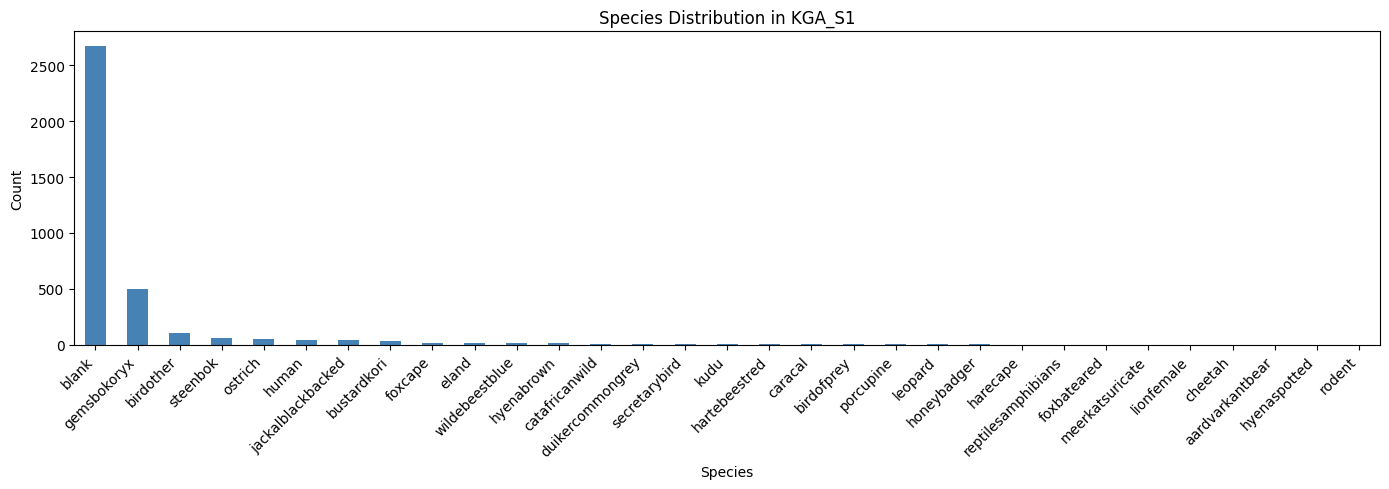

In [6]:
# Species distribution
species_counts = df['question__species'].fillna('blank').value_counts()
print('Species distribution:')
print(species_counts)

plt.figure(figsize=(14, 5))
species_counts.plot(kind='bar', color='steelblue')
plt.title('Species Distribution in KGA_S1')
plt.xlabel('Species')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 4. Build Image-Label Mapping
Match CSV rows to image files using season/site/roll folder structure.

In [7]:
def get_time_of_day(time_str):
    """Returns 'day' or 'night' from a time string HH:MM:SS"""
    try:
        t = datetime.strptime(str(time_str), '%H:%M:%S')
        return 'day' if DAY_START <= t.hour < DAY_END else 'night'
    except:
        return 'unknown'

def parse_capture_id(capture_id):
    """Parse KGA_S1#A01#1#1 -> (season, site, roll, capture)"""
    parts = capture_id.split('#')
    if len(parts) == 4:
        return parts[0], parts[1], int(parts[2]), int(parts[3])
    return None, None, None, None

def find_image_file(kga_root, season, site, roll, capture):
    """
    Images are in: KGA_ROOT/SITE/SITE_R{roll}/
    Filename pattern: KGA_S1_SITE_R{roll}_IMAG{num}.JPG
    We match by sorted order within the folder (capture index).
    """
    folder = Path(kga_root) / site / f'{site}_R{roll}'
    if not folder.exists():
        return None
    images = sorted(folder.glob('*.JPG')) + sorted(folder.glob('*.jpg'))
    # capture is 1-indexed, map to sorted image list
    idx = capture - 1
    if 0 <= idx < len(images):
        return str(images[idx])
    return None

print('Building image-label mapping...')
records = []
missing = 0

for _, row in tqdm(df.iterrows(), total=len(df)):
    season, site, roll, capture = parse_capture_id(str(row['capture_id']))
    if season is None:
        continue

    species = str(row['question__species']).strip().lower()
    if species in ('nan', '', 'blank'):
        species = 'empty'

    time_of_day = get_time_of_day(row['capture_time_local'])
    img_path = find_image_file(KGA_ROOT, season, site, roll, capture)

    if img_path is None:
        missing += 1
        continue

    records.append({
        'image_path': img_path,
        'species': species,
        'time_of_day': time_of_day,
        'is_empty': 1 if species == 'empty' else 0,
        'capture_id': row['capture_id'],
    })

mapped_df = pd.DataFrame(records)
print(f'Mapped: {len(mapped_df)} | Missing: {missing}')
mapped_df.head()


Building image-label mapping...


100%|██████████████████████████████████████████████████████████████| 3626/3626 [03:32<00:00, 17.04it/s]

Mapped: 3626 | Missing: 0


,image_path,species,time_of_day,is_empty,capture_id
0,C:\Users\dippe\Desktop\University of Botswana\...,human,day,0,KGA_S1#A01#1#1
1,C:\Users\dippe\Desktop\University of Botswana\...,human,day,0,KGA_S1#A01#1#2
2,C:\Users\dippe\Desktop\University of Botswana\...,empty,day,1,KGA_S1#A01#1#3
3,C:\Users\dippe\Desktop\University of Botswana\...,empty,day,1,KGA_S1#A01#1#4
4,C:\Users\dippe\Desktop\University of Botswana\...,empty,day,1,KGA_S1#A01#1#5


In [8]:
# Save mapping for reference
mapped_df.to_csv(os.path.join(DATASET_DIR, 'image_label_mapping.csv'), index=False)
print('Mapping saved.')

print('\nSpecies after mapping:')
print(mapped_df['species'].value_counts())
print('\nTime of day:')
print(mapped_df['time_of_day'].value_counts())


Mapping saved.

Species after mapping:
species
empty                 2672
gemsbokoryx            502
birdother              108
steenbok                58
ostrich                 46
human                   45
jackalblackbacked       39
bustardkori             34
foxcape                 19
eland                   14
wildebeestblue          13
hyenabrown              11
catafricanwild          10
duikercommongrey         9
secretarybird            9
kudu                     6
hartebeestred            5
caracal                  4
birdofprey               4
porcupine                3
leopard                  3
honeybadger              3
harecape                 1
reptilesamphibians       1
foxbateared              1
meerkatsuricate          1
lionfemale               1
cheetah                  1
aardvarkantbear          1
hyenaspotted             1
rodent                   1
Name: count, dtype: int64

Time of day:
time_of_day
day      3312
night     314
Name: count, dtype: int64


## 5. Prepare Labels & Filter Rare Classes

In [9]:
# Drop species with too few samples
species_counts = mapped_df['species'].value_counts()
valid_species = species_counts[species_counts >= MIN_SAMPLES].index.tolist()
filtered_df = mapped_df[mapped_df['species'].isin(valid_species)].copy()
print(f'Species kept (>={MIN_SAMPLES} samples): {len(valid_species)}')
print(f'Rows after filtering: {len(filtered_df)}')
print(valid_species)

# Build label encoders
species_classes = sorted(valid_species)
species2idx = {s: i for i, s in enumerate(species_classes)}
idx2species = {i: s for s, i in species2idx.items()}

tod_classes = ['day', 'night', 'unknown']
tod2idx = {t: i for i, t in enumerate(tod_classes)}

filtered_df['species_label'] = filtered_df['species'].map(species2idx)
filtered_df['tod_label'] = filtered_df['time_of_day'].map(tod2idx).fillna(2).astype(int)

print(f'\nNumber of species classes: {len(species_classes)}')
print('Classes:', species_classes)

# Save label maps
label_map = {
    'species_classes': species_classes,
    'species2idx': species2idx,
    'idx2species': idx2species,
    'tod_classes': tod_classes,
    'tod2idx': tod2idx,
}
with open(os.path.join(OUTPUT_DIR, 'label_map.json'), 'w') as f:
    json.dump(label_map, f, indent=2)
print('Label map saved.')


Species kept (>=5 samples): 17
Rows after filtering: 3600
['empty', 'gemsbokoryx', 'birdother', 'steenbok', 'ostrich', 'human', 'jackalblackbacked', 'bustardkori', 'foxcape', 'eland', 'wildebeestblue', 'hyenabrown', 'catafricanwild', 'duikercommongrey', 'secretarybird', 'kudu', 'hartebeestred']

Number of species classes: 17
Classes: ['birdother', 'bustardkori', 'catafricanwild', 'duikercommongrey', 'eland', 'empty', 'foxcape', 'gemsbokoryx', 'hartebeestred', 'human', 'hyenabrown', 'jackalblackbacked', 'kudu', 'ostrich', 'secretarybird', 'steenbok', 'wildebeestblue']
Label map saved.


## 6. Train/Val Split

In [10]:
train_df, val_df = train_test_split(
    filtered_df,
    test_size=VAL_SPLIT,
    stratify=filtered_df['species_label'],
    random_state=42
)
print(f'Train: {len(train_df)} | Val: {len(val_df)}')
print('hello')


Train: 2880 | Val: 720
hello


## 7. Dataset & DataLoader

In [11]:
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class WildlifeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            image = Image.open(row['image_path']).convert('RGB')
        except Exception:
            image = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (0, 0, 0))
        if self.transform:
            image = self.transform(image)
        return {
            'image': image,
            'species_label': torch.tensor(row['species_label'], dtype=torch.long),
            'tod_label': torch.tensor(row['tod_label'], dtype=torch.long),
            'is_empty': torch.tensor(row['is_empty'], dtype=torch.float),
        }

train_dataset = WildlifeDataset(train_df, transform=train_transforms)
val_dataset   = WildlifeDataset(val_df,   transform=val_transforms)

# Weighted sampler to handle class imbalance
class_counts = train_df['species_label'].value_counts().sort_index().values
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_df['species_label'].values]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)}')


Train batches: 90 | Val batches: 23


## 8. Model — Multi-task ResNet50

In [12]:
class WildlifeResNet(nn.Module):
    """
    ResNet50 backbone with 3 output heads:
      - species_head:  N-class species classification
      - tod_head:      3-class time-of-day (day/night/unknown)
      - empty_head:    binary empty frame detection
    """
    def __init__(self, num_species):
        super().__init__()
        backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        in_features = backbone.fc.in_features
        backbone.fc = nn.Identity()  # remove original classifier
        self.backbone = backbone

        self.species_head = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_species),
        )
        self.tod_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 3),
        )
        self.empty_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        features = self.backbone(x)
        return {
            'species': self.species_head(features),
            'tod':     self.tod_head(features),
            'empty':   self.empty_head(features).squeeze(1),
        }

num_species = len(species_classes)
model = WildlifeResNet(num_species=num_species).to(device)
print(f'Model ready. Species classes: {num_species}')

# Freeze backbone initially, train only heads
for param in model.backbone.parameters():
    param.requires_grad = False
print('Backbone frozen for warm-up phase.')


Model ready. Species classes: 17
Backbone frozen for warm-up phase.


## 9. Loss, Optimizer & Scheduler

In [13]:
species_loss_fn = nn.CrossEntropyLoss()
tod_loss_fn     = nn.CrossEntropyLoss()
empty_loss_fn   = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

# Loss weights
W_SPECIES = 1.0
W_TOD     = 0.3
W_EMPTY   = 0.5

print('done!')

done!


## 10. Training Loop

In [14]:
print('start')
def run_epoch(loader, training=True):
    model.train() if training else model.eval()
    total_loss = 0
    species_correct = 0
    tod_correct = 0
    empty_correct = 0
    total = 0

    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for batch in tqdm(loader, leave=False):
            images      = batch['image'].to(device)
            sp_labels   = batch['species_label'].to(device)
            tod_labels  = batch['tod_label'].to(device)
            empty_labels= batch['is_empty'].to(device)

            outputs = model(images)

            loss_sp  = species_loss_fn(outputs['species'], sp_labels)
            loss_tod = tod_loss_fn(outputs['tod'], tod_labels)
            loss_emp = empty_loss_fn(outputs['empty'], empty_labels)
            loss = W_SPECIES * loss_sp + W_TOD * loss_tod + W_EMPTY * loss_emp

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * len(images)
            total += len(images)

            species_correct += (outputs['species'].argmax(1) == sp_labels).sum().item()
            tod_correct     += (outputs['tod'].argmax(1) == tod_labels).sum().item()
            empty_pred = (torch.sigmoid(outputs['empty']) > 0.5).float()
            empty_correct   += (empty_pred == empty_labels).sum().item()

    return {
        'loss':           total_loss / total,
        'species_acc':    species_correct / total,
        'tod_acc':        tod_correct / total,
        'empty_acc':      empty_correct / total,
    }

history = {'train': [], 'val': []}
best_val_acc = 0
WARMUP_EPOCHS = 3

print('Starting training...')
for epoch in range(1, NUM_EPOCHS + 1):

    # Unfreeze backbone after warmup
    if epoch == WARMUP_EPOCHS + 1:
        print('Unfreezing backbone for fine-tuning...')
        for param in model.backbone.parameters():
            param.requires_grad = True
        optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE * 0.1, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS)

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics   = run_epoch(val_loader,   training=False)
    scheduler.step()

    history['train'].append(train_metrics)
    history['val'].append(val_metrics)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
          f"Train Loss: {train_metrics['loss']:.4f} | "
          f"Val Loss: {val_metrics['loss']:.4f} | "
          f"Val Species Acc: {val_metrics['species_acc']:.3f} | "
          f"Val Empty Acc: {val_metrics['empty_acc']:.3f}")

    # Save best model
    if val_metrics['species_acc'] > best_val_acc:
        best_val_acc = val_metrics['species_acc']
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_species_acc': best_val_acc,
            'num_species': num_species,
            'species_classes': species_classes,
            'tod_classes': tod_classes,
        }, os.path.join(OUTPUT_DIR, 'resnet50_wildlife_best.pth'))
        print(f'  -> Best model saved (val acc: {best_val_acc:.3f})')

print('Training complete!')


start
Starting training...


Epoch 01/20 | Train Loss: 3.1616 | Val Loss: 3.5501 | Val Species Acc: 0.399 | Val Empty Acc: 0.258
  -> Best model saved (val acc: 0.399)


Epoch 02/20 | Train Loss: 2.7318 | Val Loss: 3.5225 | Val Species Acc: 0.381 | Val Empty Acc: 0.258


Epoch 03/20 | Train Loss: 2.3770 | Val Loss: 3.2049 | Val Species Acc: 0.422 | Val Empty Acc: 0.258
  -> Best model saved (val acc: 0.422)
Unfreezing backbone for fine-tuning...


Epoch 04/20 | Train Loss: 2.0047 | Val Loss: 3.4026 | Val Species Acc: 0.431 | Val Empty Acc: 0.258
  -> Best model saved (val acc: 0.431)


Epoch 05/20 | Train Loss: 1.7442 | Val Loss: 3.3582 | Val Species Acc: 0.446 | Val Empty Acc: 0.258
  -> Best model saved (val acc: 0.446)


... (11 outputs left out)

Epoch 17/20 | Train Loss: 1.1466 | Val Loss: 2.7091 | Val Species Acc: 0.483 | Val Empty Acc: 0.346


Epoch 18/20 | Train Loss: 1.1060 | Val Loss: 2.7423 | Val Species Acc: 0.469 | Val Empty Acc: 0.321


Epoch 19/20 | Train Loss: 1.1110 | Val Loss: 2.6791 | Val Species Acc: 0.490 | Val Empty Acc: 0.350


Epoch 20/20 | Train Loss: 1.0638 | Val Loss: 2.6772 | Val Species Acc: 0.494 | Val Empty Acc: 0.344
  -> Best model saved (val acc: 0.494)
Training complete!


## 11. Training Curves

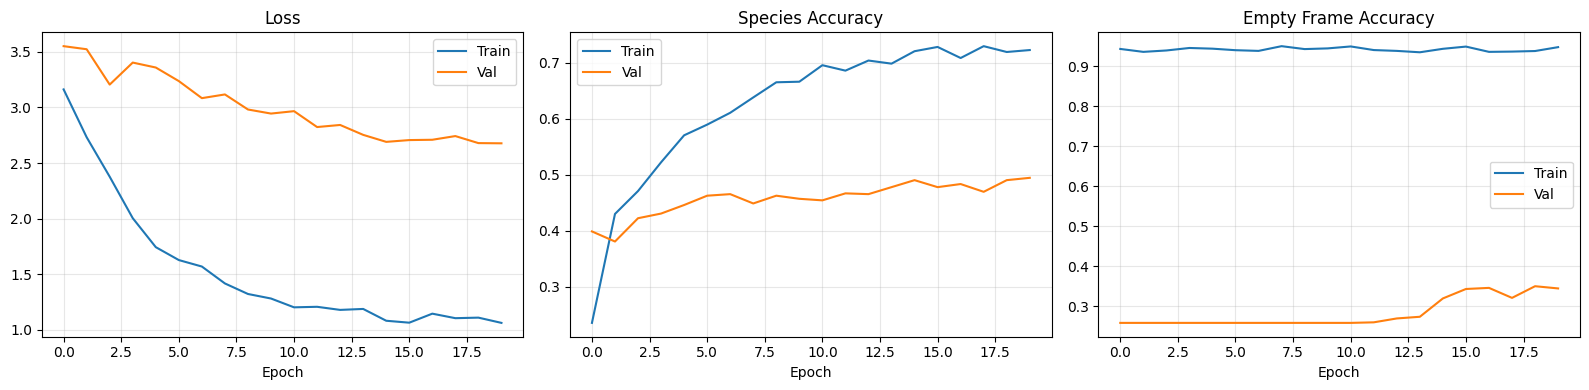

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = ['loss', 'species_acc', 'empty_acc']
titles  = ['Loss', 'Species Accuracy', 'Empty Frame Accuracy']

for ax, metric, title in zip(axes, metrics, titles):
    ax.plot([m[metric] for m in history['train']], label='Train')
    ax.plot([m[metric] for m in history['val']],   label='Val')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_curves.png'), dpi=150)
plt.show()


## 12. Evaluation on Validation Set

In [16]:
# Load best model
checkpoint = torch.load(os.path.join(OUTPUT_DIR, 'resnet50_wildlife_best.pth'), map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

all_sp_preds, all_sp_labels = [], []

with torch.no_grad():
    for batch in tqdm(val_loader):
        images   = batch['image'].to(device)
        sp_labels = batch['species_label']
        outputs  = model(images)
        preds    = outputs['species'].argmax(1).cpu()
        all_sp_preds.extend(preds.numpy())
        all_sp_labels.extend(sp_labels.numpy())

print('Classification Report:')
print(classification_report(
    all_sp_labels, all_sp_preds,
    target_names=species_classes,
    zero_division=0
))


C:\Users\dippe\AppData\Local\Temp\ipykernel_37876\1372904479.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(os.path.join(OUTPUT_DIR, 'resnet50_w

Classification Report:
                   precision    recall  f1-score   support

        birdother       0.18      0.55      0.27        22
      bustardkori       0.21      0.43      0.29         7
   catafricanwild       0.00      0.00      0.00         2
 duikercommongrey       0.00      0.00      0.00         2
            eland       0.33      1.00      0.50         3
            empty       0.98      0.53      0.68       534
          foxcape       0.08      0.50      0.13         4
      gemsbokoryx       0.63      0.40      0.49       100
    hartebeestred       0.00      0.00      0.00         1
            human       0.03      0.11      0.05         9
       hyenabrown       0.00      0.00      0.00         2
jackalblackbacked       0.02      0.12      0.04         8
             kudu       0.20      1.00      0.33         1
          ostrich       0.36      1.00      0.53         9
    secretarybird       0.50      0.50      0.50         2
         steenbok       0.04    

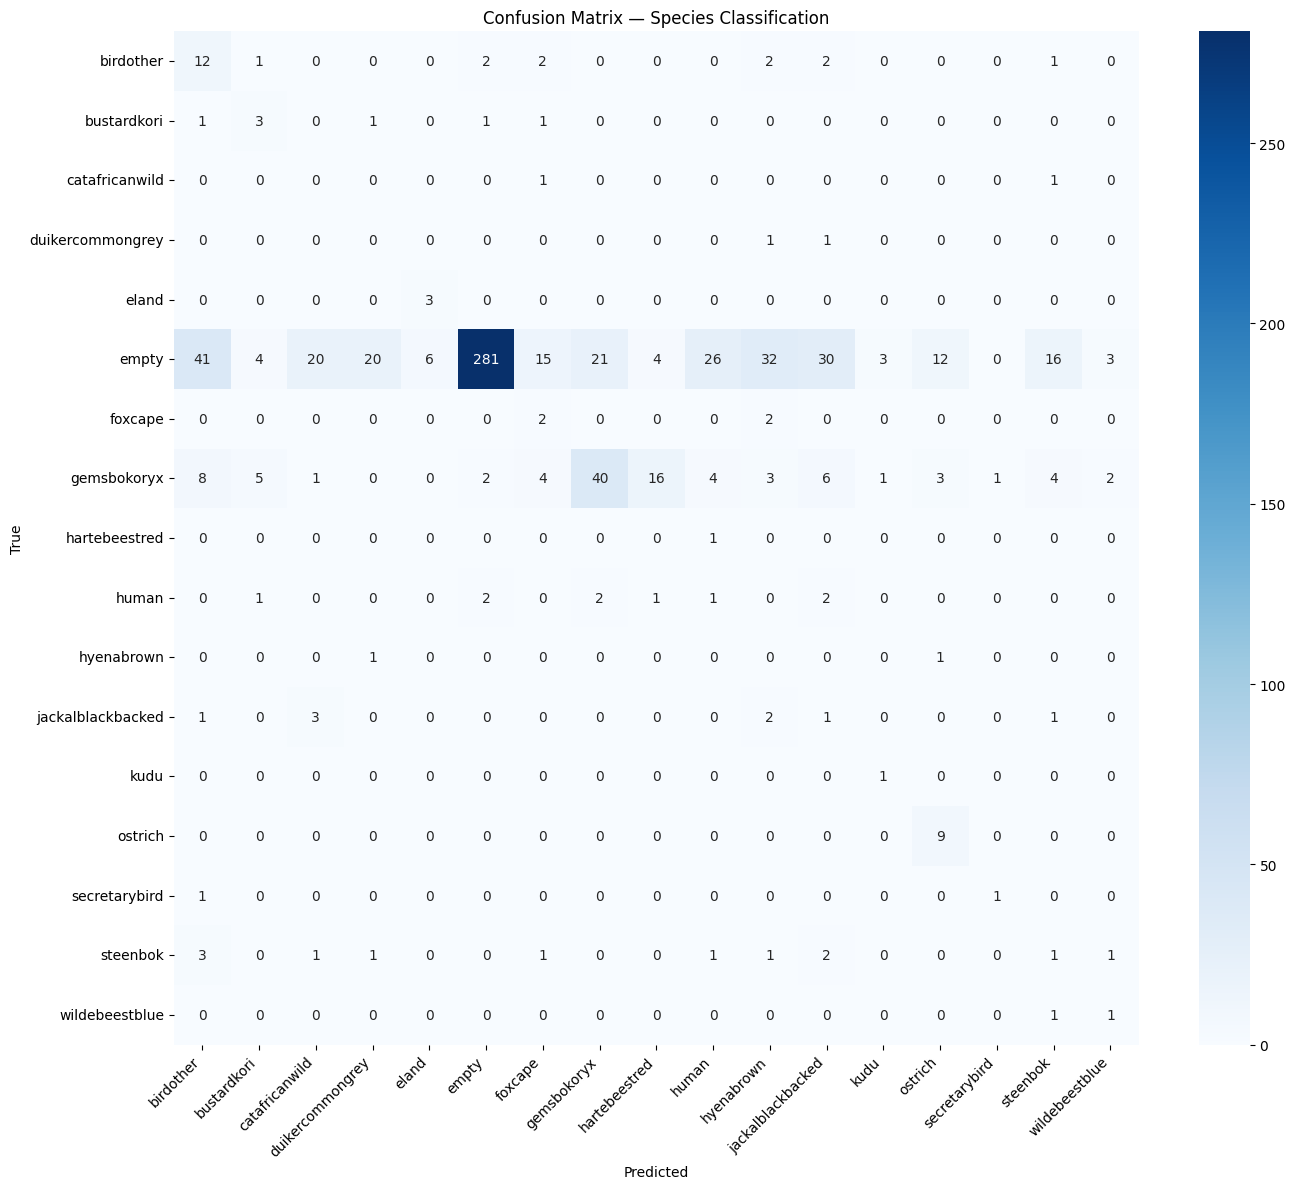

In [17]:
# Confusion matrix
cm = confusion_matrix(all_sp_labels, all_sp_preds)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=species_classes, yticklabels=species_classes)
plt.title('Confusion Matrix — Species Classification')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()


## 13. Single Image Inference Test

Image: C:\Users\dippe\Desktop\University of Botswana\Semester 8\KGA_S1\B06\B06_R1\KGA_S1_B06_R1_IMAG0240.JPG
True species:  empty
Predicted:     empty (72.13% confidence)
Time of day:   day
Empty frame:   True
Top 3: [{'species': 'empty', 'confidence': 72.13}, {'species': 'hyenabrown', 'confidence': 7.25}, {'species': 'birdother', 'confidence': 6.02}]


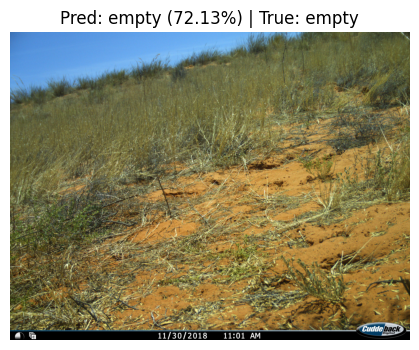

In [20]:
def predict_image(image_path, model, label_map, device):
    """Run inference on a single image and return predictions."""
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    image = Image.open(image_path).convert('RGB')
    tensor = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(tensor)

    species_probs = torch.softmax(outputs['species'], dim=1)[0]
    species_idx   = species_probs.argmax().item()
    species_conf  = species_probs[species_idx].item()

    tod_idx  = outputs['tod'].argmax(1).item()
    is_empty = torch.sigmoid(outputs['empty']).item() > 0.5

    return {
        'species':          label_map['species_classes'][species_idx],
        'confidence':       round(species_conf * 100, 2),
        'time_of_day':      label_map['tod_classes'][tod_idx],
        'is_empty':         is_empty,
        'top3':             [
            {'species': label_map['species_classes'][i], 'confidence': round(species_probs[i].item() * 100, 2)}
            for i in species_probs.topk(3).indices.tolist()
        ]
    }

# Test on a sample image
sample_row = val_df.iloc[0]
result = predict_image(sample_row['image_path'], model, label_map, device)

print(f"Image: {sample_row['image_path']}")
print(f"True species:  {sample_row['species']}")
print(f"Predicted:     {result['species']} ({result['confidence']}% confidence)")
print(f"Time of day:   {result['time_of_day']}")
print(f"Empty frame:   {result['is_empty']}")
print(f"Top 3: {result['top3']}")

# Show image
img = Image.open(sample_row['image_path'])
plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.title(f"Pred: {result['species']} ({result['confidence']}%) | True: {sample_row['species']}")
plt.axis('off')
plt.show()


## 14. Export Model Info

In [21]:
model_info = {
    'architecture': 'ResNet50',
    'num_species': num_species,
    'species_classes': species_classes,
    'tod_classes': tod_classes,
    'img_size': IMG_SIZE,
    'best_val_species_acc': best_val_acc,
    'checkpoint': 'resnet50_wildlife_best.pth',
}
with open(os.path.join(OUTPUT_DIR, 'model_info.json'), 'w') as f:
    json.dump(model_info, f, indent=2)

print('Model info saved.')
print(json.dumps(model_info, indent=2))


Model info saved.
{
  "architecture": "ResNet50",
  "num_species": 17,
  "species_classes": [
    "birdother",
    "bustardkori",
    "catafricanwild",
    "duikercommongrey",
    "eland",
    "empty",
    "foxcape",
    "gemsbokoryx",
    "hartebeestred",
    "human",
    "hyenabrown",
    "jackalblackbacked",
    "kudu",
    "ostrich",
    "secretarybird",
    "steenbok",
    "wildebeestblue"
  ],
  "tod_classes": [
    "day",
    "night",
    "unknown"
  ],
  "img_size": 224,
  "best_val_species_acc": 0.49444444444444446,
  "checkpoint": "resnet50_wildlife_best.pth"
}
